# Gas-drag migration in a dispersing disk

Separate orbit-averaged tracks for **aerodynamic gas drag only** and **Type-I migration only**. The two rates are never added. The drag acceleration follows the planar, `UsegasDrag` branch in `examples/dataset/gas_config/gas.cu`; the gas surface density and scale height come from `accrediff.gas_migration`. The gas-potential, enhanced-drag and tidal-damping switches are off. No GENGA simulation is run here. The Type-I branch uses the existing torque and CN08 eccentricity damping functions from `accrediff.gas_migration`.

The reference disk uses the settings in `gas_profile.ipynb`. Initial orbits span 0.5–4 AU and four particle masses. The first-stage calculation assumes coplanar orbits; `e0` and all plotted parameters can be changed below. Orbital averaging is appropriate when migration and eccentricity damping are slow compared with one orbital period.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "src" / "accrediff").exists()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate the AccreDiff repository root")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from accrediff.gas_migration import Gas_ModelConfig, Gas_build_model

## Editable parameters

The adopted solid density and drag coefficient match `run_gas_drag_type1.ipynb`. Set `e0` to a different starting eccentricity as needed. Inclination is fixed to zero in this planar version.

In [18]:
masses_mearth = (1e-6, 1e-5, 1e-4, 1e-2)
initial_a_au = (0.5, 1.0, 2.0, 3.0, 4.0)
e0 = 0.01
t_max_myr = 5.0
n_output = 300
n_orbit_samples = 96
solid_density_cgs = 2.0
drag_coefficient = 0.5
a_min_stop = 0.05

disk_cfg = Gas_ModelConfig(
    particle_mass_mearth=masses_mearth[0],
    a0=initial_a_au[0],
    tau_decay_myr=1.0,
    a_alpha1=1.0,
    a_alpha2=0.5,
    Sigma0_cgs=1700.0,
    alpha_visc=1e-4,
    prandtl=1.0,
    use_saturation=True,
    t_max_myr=t_max_myr,
)
gas_model = Gas_build_model(disk_cfg)
disk, units = gas_model["disk"], gas_model["units"]

assert all(m > 0 for m in masses_mearth)
assert all(a > a_min_stop for a in initial_a_au)
assert 0 <= e0 < 1 and t_max_myr > 0 and n_orbit_samples >= 16
assert solid_density_cgs > 0 and drag_coefficient > 0

## Orbit-averaged drag rates

At evenly spaced eccentric anomalies, compute Kepler position and velocity, the local gas velocity, and the quadratic drag acceleration. The average uses the mean-anomaly weight `dM = (1-e cos E)dE`. Both rates come from this same acceleration: orbital-energy change gives `da/dt`, and the eccentricity-vector derivative gives `de/dt`. This avoids dividing by `e` near circular orbits.

The `gas.cu` coefficient is `π C_D R² ρ/(2m)`. Here `R` is the physical radius implied by mass and solid density. We use its local pressure-gradient term with the Python disk's local `p(r) = -d ln Σ/d ln r`; gas self-gravity is off, so the gas circular speed is Keplerian before the pressure correction.

In [19]:
def orbit_averaged_drag_rates(t_myr, a_au, e, mass_mearth, disk_model=None, unit_system=None):
    """Return (da/dt [AU/Myr], de/dt [1/Myr]) for coplanar gas drag."""
    if a_au <= 0 or not 0 <= e < 1:
        raise ValueError("Require a > 0 and 0 <= e < 1")
    disk_model = disk if disk_model is None else disk_model
    unit_system = units if unit_system is None else unit_system
    cfg = disk_model.cfg
    mu = cfg.G * cfg.Mstar
    m_code = mass_mearth * cfg.Mearth_to_Msun
    m_g = m_code * cfg.Msun_in_g
    radius_code = (3 * m_g / (4 * np.pi * solid_density_cgs)) ** (1/3) / cfg.AU_in_cm

    E = 2 * np.pi * (np.arange(n_orbit_samples) + 0.5) / n_orbit_samples
    ce, se = np.cos(E), np.sin(E)
    root = np.sqrt(1 - e*e)
    weight = 1 - e * ce  # dM/dE
    x, y = a_au * (ce - e), a_au * root * se
    r = a_au * weight
    vscale = np.sqrt(mu / a_au) / weight
    vx, vy = -vscale * se, vscale * root * ce

    t_code = unit_system.myr_to_code(t_myr)
    H = disk_model.scale_height(r)
    rho_code = disk_model.sigma(r, t_code) / (np.sqrt(2*np.pi) * H)
    eta = 0.5 * (disk_model.sigma_slope_p(r) + 1.75) * (H / r)**2
    v_gas = np.sqrt(mu / r) * (1 - eta)
    ux, uy = vx + v_gas * y/r, vy - v_gas * x/r
    uabs = np.hypot(ux, uy)
    coeff = np.pi * drag_coefficient * radius_code**2 * rho_code / (2*m_code)
    fx, fy = -coeff * uabs * ux, -coeff * uabs * uy

    energy_dot = vx*fx + vy*fy
    h = x*vy - y*vx
    h_dot = x*fy - y*fx
    da_code = 2*a_au*a_au*energy_dot/mu
    de_code = (fy*h + vy*h_dot)/mu  # x component of d(e-vector)/dt
    code_per_myr = 1 / unit_system.MYR_PER_CODE
    return (np.mean(da_code*weight)*code_per_myr,
            np.mean(de_code*weight)*code_per_myr)


def drag_only_rates(t_myr, a_au, e, mass_mearth):
    """Aerodynamic branch; deliberately excludes Type-I rates."""
    return orbit_averaged_drag_rates(t_myr, a_au, e, mass_mearth)

## Integrate each mass and initial orbit

The integrator stops if the semimajor axis reaches `a_min_stop`. Values beyond a stop are left as `NaN` in the common output grid; they are not drawn as artificial flat tracks.

In [20]:
t_plot = np.linspace(0, t_max_myr, n_output)

def integrate_track(mass_mearth, a0_au):
    def rhs(t, state):
        a, e = state
        return drag_only_rates(t, max(a, a_min_stop), np.clip(e, 0, 0.999), mass_mearth)

    def inner_edge(t, state):
        return state[0] - a_min_stop
    inner_edge.terminal = True
    inner_edge.direction = -1

    sol = solve_ivp(rhs, (0, t_max_myr), (a0_au, e0),
                    dense_output=True, events=inner_edge,
                    rtol=1e-7, atol=1e-10, max_step=0.05)
    if not sol.success:
        raise RuntimeError(sol.message)
    a = np.full_like(t_plot, np.nan)
    e = np.full_like(t_plot, np.nan)
    valid = t_plot <= sol.t[-1] + 1e-12
    a[valid], e[valid] = sol.sol(t_plot[valid])
    e[valid] = np.maximum(e[valid], 0)
    return {"t_myr": t_plot, "a_au": a, "e": e,
            "stop_myr": sol.t[-1] if sol.t[-1] < t_max_myr else None}

tracks = {(m, a0): integrate_track(m, a0)
          for m in masses_mearth for a0 in initial_a_au}
for m in masses_mearth:
    for a0 in initial_a_au:
        tr = tracks[m, a0]
        print(f"m={m:.0e} Mearth, a0={a0:g} AU: "
              f"a_end={tr['a_au'][np.isfinite(tr['a_au'])][-1]:.4f} AU, "
              f"e_end={tr['e'][np.isfinite(tr['e'])][-1]:.4g}, "
              f"stop={tr['stop_myr']}")

m=1e-06 Mearth, a0=0.5 AU: a_end=0.4985 AU, e_end=0.0001753, stop=None
m=1e-06 Mearth, a0=1 AU: a_end=0.9919 AU, e_end=0.0003156, stop=None
m=1e-06 Mearth, a0=2 AU: a_end=1.9874 AU, e_end=0.003383, stop=None
m=1e-06 Mearth, a0=3 AU: a_end=2.9919 AU, e_end=0.007342, stop=None
m=1e-06 Mearth, a0=4 AU: a_end=3.9959 AU, e_end=0.009083, stop=None
m=1e-05 Mearth, a0=0.5 AU: a_end=0.4988 AU, e_end=0.0005804, stop=None
m=1e-05 Mearth, a0=1 AU: a_end=0.9944 AU, e_end=0.001294, stop=None
m=1e-05 Mearth, a0=2 AU: a_end=1.9928 AU, e_end=0.005638, stop=None
m=1e-05 Mearth, a0=3 AU: a_end=2.9960 AU, e_end=0.008616, stop=None
m=1e-05 Mearth, a0=4 AU: a_end=3.9980 AU, e_end=0.009559, stop=None
m=1e-04 Mearth, a0=0.5 AU: a_end=0.4991 AU, e_end=0.001295, stop=None
m=1e-04 Mearth, a0=1 AU: a_end=0.9962 AU, e_end=0.002862, stop=None
m=1e-04 Mearth, a0=2 AU: a_end=1.9962 AU, e_end=0.007472, stop=None
m=1e-04 Mearth, a0=3 AU: a_end=2.9981 AU, e_end=0.009319, stop=None
m=1e-04 Mearth, a0=4 AU: a_end=3.9991 A

## Type-I-only tracks

For each mass and starting orbit, build the existing `Gas_MigrationIntegrator` with the same disk parameters. Its `da_dt_eccentric` uses the Type-I torque and CN08 eccentricity correction; `de_dt` uses CN08 eccentricity damping. **No aerodynamic drag is called in this branch.** We use the same output times and numerical tolerances as the drag-only branch for direct comparison.

In [21]:
from dataclasses import replace


def integrate_type1_track(mass_mearth, a0_au):
    type1_cfg = replace(disk_cfg, particle_mass_mearth=mass_mearth, a0=a0_au)
    type1_model = Gas_build_model(type1_cfg)
    integrator = type1_model["integrator"]
    type1_units = type1_model["units"]

    def rhs(t, state):
        a, e = state
        a = max(a, a_min_stop)
        e = np.clip(e, 0, 0.999)
        t_code = type1_units.myr_to_code(t)
        a_code = np.array([a])
        e_code = np.array([e])
        inc_code = np.array([0.0])
        da = integrator.da_dt_eccentric(t_code, a_code, e_code, inc_code)[0]
        de = integrator.de_dt(t_code, a_code, e_code, inc_code)[0]
        return np.array([da, de]) / type1_units.MYR_PER_CODE

    def inner_edge(t, state):
        return state[0] - a_min_stop
    inner_edge.terminal = True
    inner_edge.direction = -1

    def outer_edge(t, state):
        return disk_cfg.a_max_stop - state[0]
    outer_edge.terminal = True
    outer_edge.direction = -1

    sol = solve_ivp(rhs, (0, t_max_myr), (a0_au, e0), dense_output=True,
                    events=(inner_edge, outer_edge), rtol=1e-7, atol=1e-10,
                    max_step=0.05)
    if not sol.success:
        raise RuntimeError(sol.message)
    a = np.full_like(t_plot, np.nan)
    e = np.full_like(t_plot, np.nan)
    valid = t_plot <= sol.t[-1] + 1e-12
    a[valid], e[valid] = sol.sol(t_plot[valid])
    e[valid] = np.maximum(e[valid], 0)
    return {"t_myr": t_plot, "a_au": a, "e": e,
            "stop_myr": sol.t[-1] if sol.t[-1] < t_max_myr else None}


type1_tracks = {(m, a0): integrate_type1_track(m, a0)
                for m in masses_mearth for a0 in initial_a_au}

## Direct comparison: independent mechanisms

Each color denotes one starting orbit. Solid lines show gas drag only; dashed lines show Type-I only. No curve contains their sum.

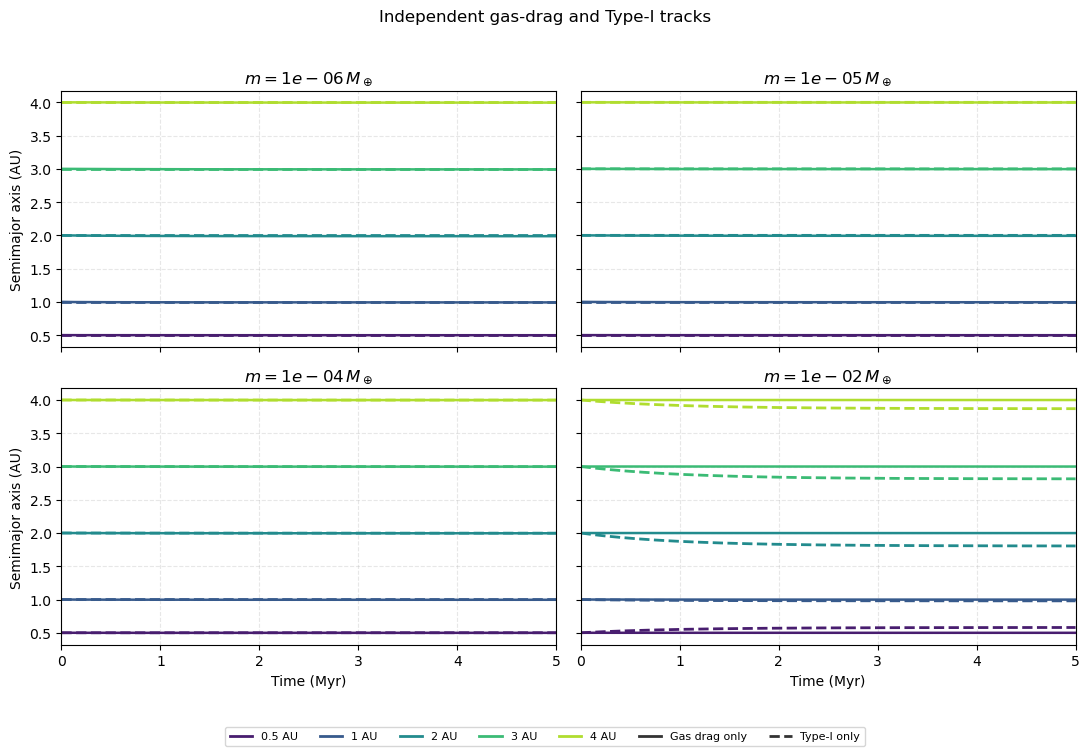

mass (Mearth)  a0 (AU)  drag final (AU)  Type-I final (AU)  Type-I − drag (AU)
       1e-06      0.5         0.498488           0.500008            0.001520
       1e-06      1.0         0.991882           0.999997            0.008115
       1e-06      2.0         1.987400           1.999980            0.012580
       1e-06      3.0         2.991912           2.999982            0.008070
       1e-06      4.0         3.995860           3.999987            0.004127
       1e-05      0.5         0.498814           0.500077            0.001263
       1e-05      1.0         0.994414           0.999973            0.005559
       1e-05      2.0         1.992760           1.999798            0.007038
       1e-05      3.0         2.995984           2.999818            0.003835
       1e-05      4.0         3.998040           3.999872            0.001832
       1e-04      0.5         0.499107           0.500775            0.001668
       1e-04      1.0         0.996242           0.999735      

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True, sharey=True)
colors = plt.cm.viridis(np.linspace(0.08, 0.88, len(initial_a_au)))
for ax, m in zip(axes.flat, masses_mearth):
    for a0, color in zip(initial_a_au, colors):
        drag = tracks[m, a0]
        type1 = type1_tracks[m, a0]
        ax.plot(drag["t_myr"], drag["a_au"], color=color, lw=1.8, ls="-")
        ax.plot(type1["t_myr"], type1["a_au"], color=color, lw=2, ls="--")
    ax.set_title(fr"$m={m:.0e}\,M_\oplus$")
    ax.grid(alpha=0.3, ls="--")
    ax.set_xlim(0, t_max_myr)
for ax in axes[:, 0]: ax.set_ylabel("Semimajor axis (AU)")
for ax in axes[-1, :]: ax.set_xlabel("Time (Myr)")
from matplotlib.lines import Line2D
orbit_handles = [Line2D([0], [0], color=c, lw=2, label=f"{a0:g} AU")
                 for a0, c in zip(initial_a_au, colors)]
mechanism_handles = [Line2D([0], [0], color="0.2", lw=2, ls="-", label="Gas drag only"),
                     Line2D([0], [0], color="0.2", lw=2, ls="--", label="Type-I only")]
fig.legend(handles=orbit_handles + mechanism_handles, loc="lower center",
           ncol=len(initial_a_au)+2, fontsize=8, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Independent gas-drag and Type-I tracks")
fig.tight_layout(rect=(0, 0.055, 1, 0.96))
plt.show()

print("mass (Mearth)  a0 (AU)  drag final (AU)  Type-I final (AU)  Type-I − drag (AU)")
for m in masses_mearth:
    for a0 in initial_a_au:
        drag_a = tracks[m, a0]["a_au"]
        type1_a = type1_tracks[m, a0]["a_au"]
        d = drag_a[np.isfinite(drag_a)][-1]
        t = type1_a[np.isfinite(type1_a)][-1]
        print(f"{m:12.0e}  {a0:7.1f}  {d:15.6f}  {t:17.6f}  {t-d:18.6f}")

### Signed displacement comparison

`a0-a(t)` is positive for inward migration and negative for outward migration. The same color and line style convention applies. Each mass panel chooses its own vertical range so that small changes remain visible.

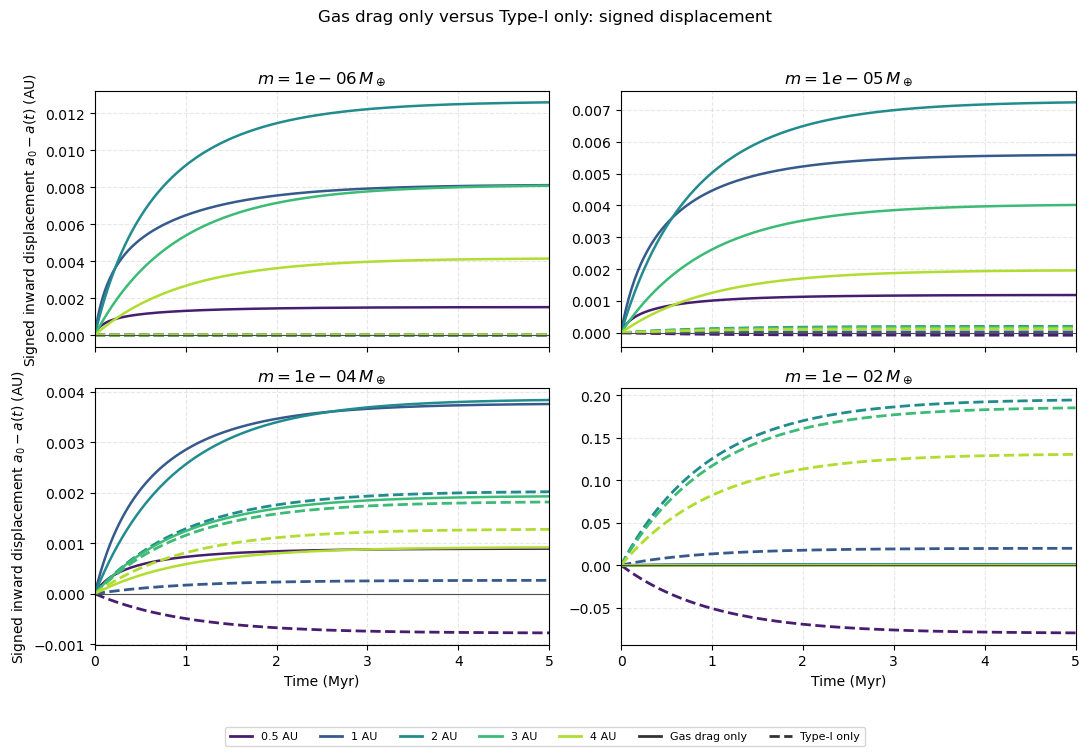

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
for ax, m in zip(axes.flat, masses_mearth):
    for a0, color in zip(initial_a_au, colors):
        drag = tracks[m, a0]
        type1 = type1_tracks[m, a0]
        ax.plot(drag["t_myr"], a0-drag["a_au"], color=color, lw=1.8, ls="-")
        ax.plot(type1["t_myr"], a0-type1["a_au"], color=color, lw=2, ls="--")
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set_title(fr"$m={m:.0e}\,M_\oplus$")
    ax.grid(alpha=0.3, ls="--")
    ax.set_xlim(0, t_max_myr)
for ax in axes[:, 0]: ax.set_ylabel(r"Signed inward displacement $a_0-a(t)$ (AU)")
for ax in axes[-1, :]: ax.set_xlabel("Time (Myr)")
fig.legend(handles=orbit_handles + mechanism_handles, loc="lower center",
           ncol=len(initial_a_au)+2, fontsize=8, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Gas drag only versus Type-I only: signed displacement")
fig.tight_layout(rect=(0, 0.055, 1, 0.96))
plt.show()

## Semimajor-axis tracks and eccentricity damping

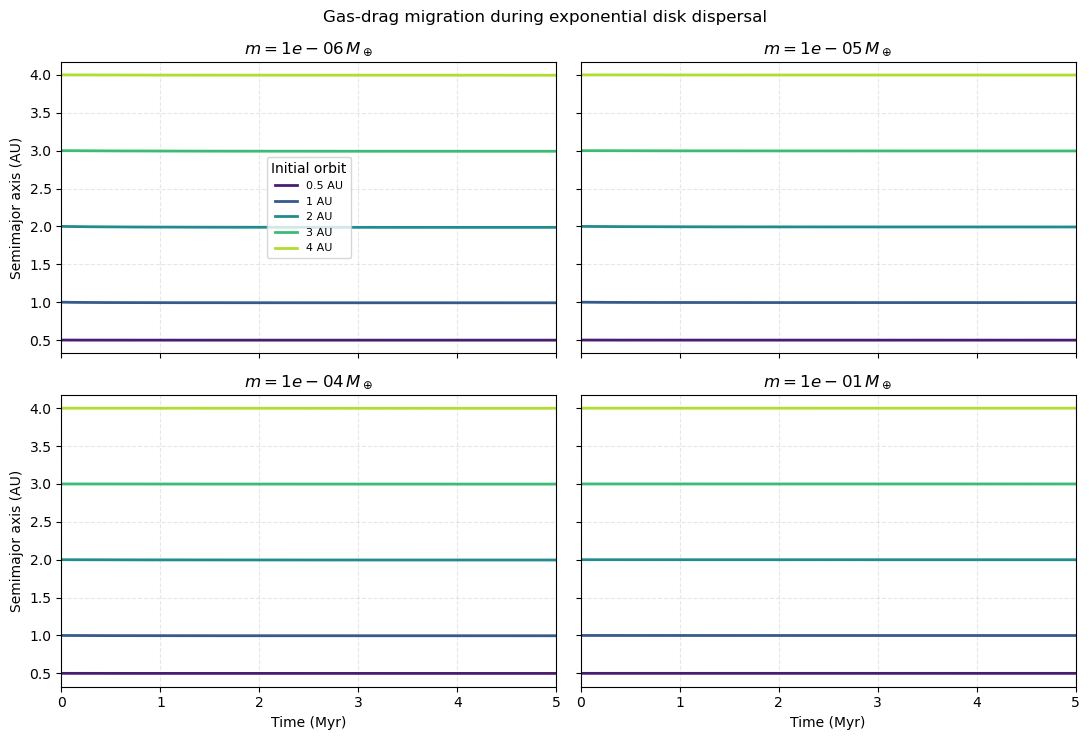

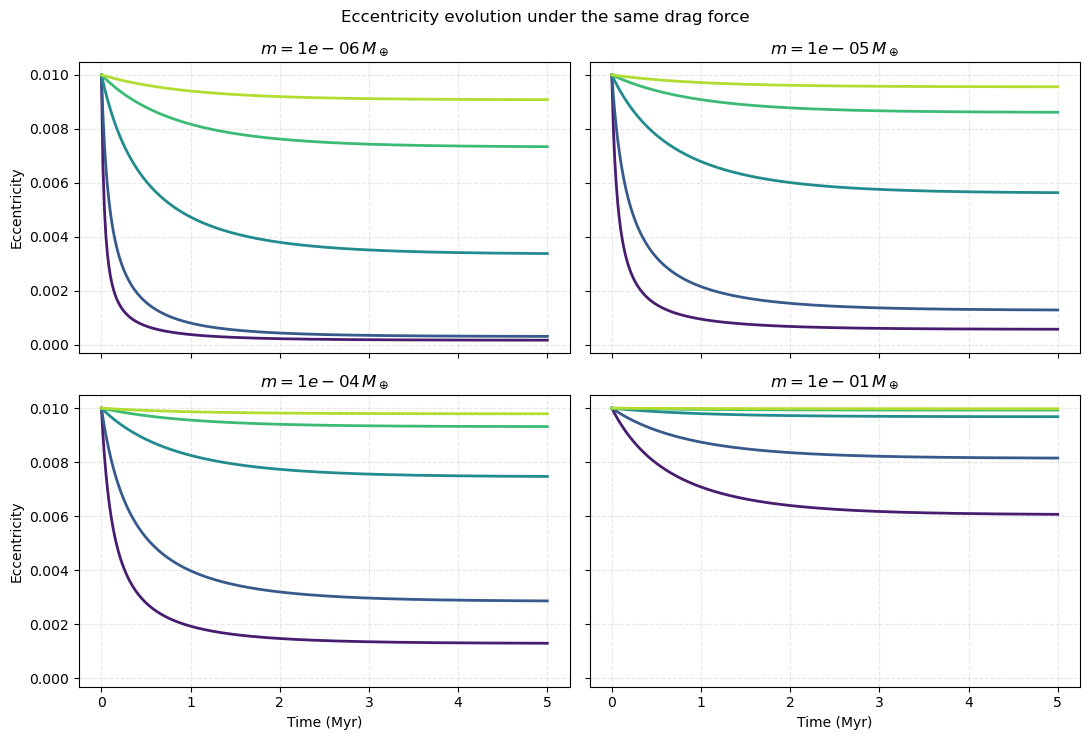

In [17]:
colors = plt.cm.viridis(np.linspace(0.08, 0.88, len(initial_a_au)))
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True, sharey=True)
for ax, m in zip(axes.flat, masses_mearth):
    for a0, color in zip(initial_a_au, colors):
        tr = tracks[m, a0]
        ax.plot(tr["t_myr"], tr["a_au"], lw=2, color=color, label=f"{a0:g} AU")
    ax.set_title(fr"$m={m:.0e}\,M_\oplus$")
    ax.grid(alpha=0.3, ls="--")
    ax.set_xlim(0, t_max_myr)
for ax in axes[:, 0]: ax.set_ylabel("Semimajor axis (AU)")
for ax in axes[-1, :]: ax.set_xlabel("Time (Myr)")
axes[0, 0].legend(title="Initial orbit", fontsize=8)
fig.suptitle("Gas-drag migration during exponential disk dispersal")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True, sharey=True)
for ax, m in zip(axes.flat, masses_mearth):
    for a0, color in zip(initial_a_au, colors):
        tr = tracks[m, a0]
        ax.plot(tr["t_myr"], tr["e"], lw=2, color=color, label=f"{a0:g} AU")
    ax.set_title(fr"$m={m:.0e}\,M_\oplus$")
    ax.grid(alpha=0.3, ls="--")
for ax in axes[:, 0]: ax.set_ylabel("Eccentricity")
for ax in axes[-1, :]: ax.set_xlabel("Time (Myr)")
fig.suptitle("Eccentricity evolution under the same drag force")
fig.tight_layout()
plt.show()

## Resolve small migration on a useful scale

The preceding plot deliberately keeps an absolute AU axis to compare the starting orbits. With gas drag alone the changes can be much smaller than its 0.5–4 AU span. The next plot shows the inward displacement `a0-a(t)` in AU; the table reports its final value and percentage for every track. These use the same results, without rescaling the physics.

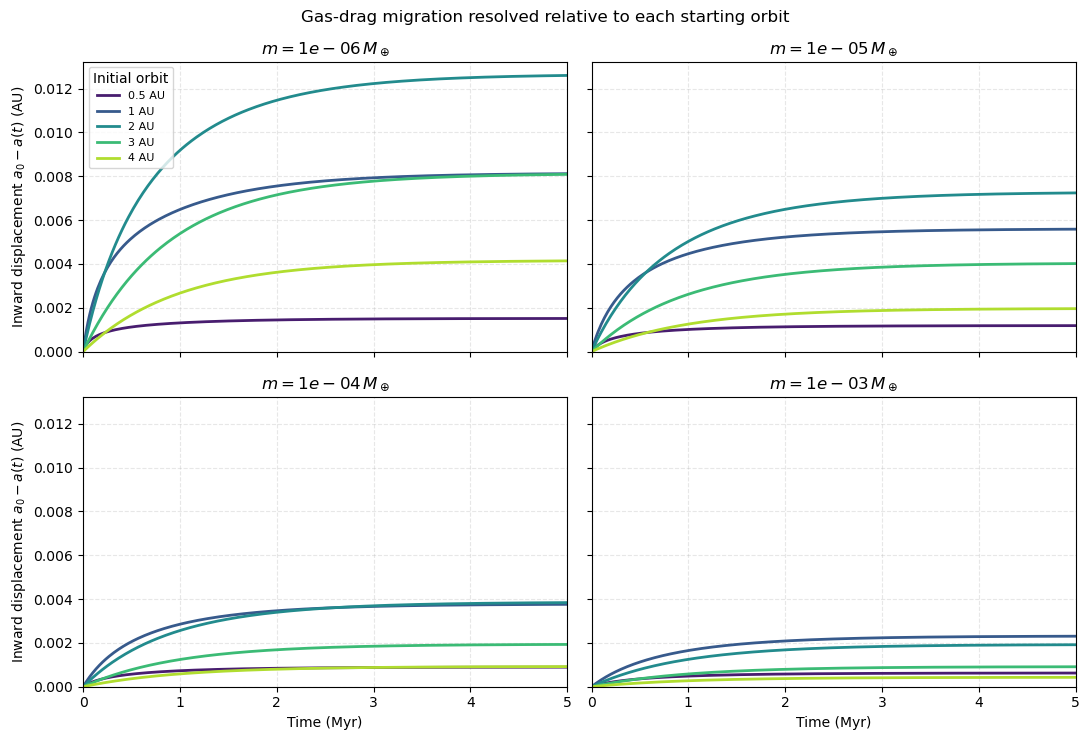

mass (Mearth)   a0 (AU)   final a (AU)   inward Δa (AU)   inward (%)
       1e-06       0.5       0.498488         0.001512       0.3024
       1e-06       1.0       0.991882         0.008118       0.8118
       1e-06       2.0       1.987400         0.012600       0.6300
       1e-06       3.0       2.991912         0.008088       0.2696
       1e-06       4.0       3.995860         0.004140       0.1035
       1e-05       0.5       0.498814         0.001186       0.2371
       1e-05       1.0       0.994414         0.005586       0.5586
       1e-05       2.0       1.992760         0.007240       0.3620
       1e-05       3.0       2.995984         0.004016       0.1339
       1e-05       4.0       3.998040         0.001960       0.0490
       1e-04       0.5       0.499107         0.000893       0.1785
       1e-04       1.0       0.996242         0.003758       0.3758
       1e-04       2.0       1.996162         0.003838       0.1919
       1e-04       3.0       2.998070         0

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True, sharey=True)
summary = []
for ax, m in zip(axes.flat, masses_mearth):
    for a0, color in zip(initial_a_au, colors):
        tr = tracks[m, a0]
        displacement = a0 - tr["a_au"]
        ax.plot(tr["t_myr"], displacement, lw=2, color=color, label=f"{a0:g} AU")
        final_a = tr["a_au"][np.isfinite(tr["a_au"])][-1]
        summary.append((m, a0, final_a, a0-final_a, 100*(a0-final_a)/a0))
    ax.set_title(fr"$m={m:.0e}\,M_\oplus$")
    ax.grid(alpha=0.3, ls="--")
    ax.set_xlim(0, t_max_myr)
    ax.set_ylim(bottom=0)
for ax in axes[:, 0]: ax.set_ylabel(r"Inward displacement $a_0-a(t)$ (AU)")
for ax in axes[-1, :]: ax.set_xlabel("Time (Myr)")
axes[0, 0].legend(title="Initial orbit", fontsize=8)
fig.suptitle("Gas-drag migration resolved relative to each starting orbit")
fig.tight_layout()
plt.show()

print("mass (Mearth)   a0 (AU)   final a (AU)   inward Δa (AU)   inward (%)")
for m, a0, final_a, delta_a, percent in summary:
    print(f"{m:12.0e}   {a0:7.1f}   {final_a:12.6f}   {delta_a:14.6f}   {percent:10.4f}")

## Disk dispersal diagnostic

Show gas surface density at fixed radii, separately from the changing density encountered along each particle's orbit.

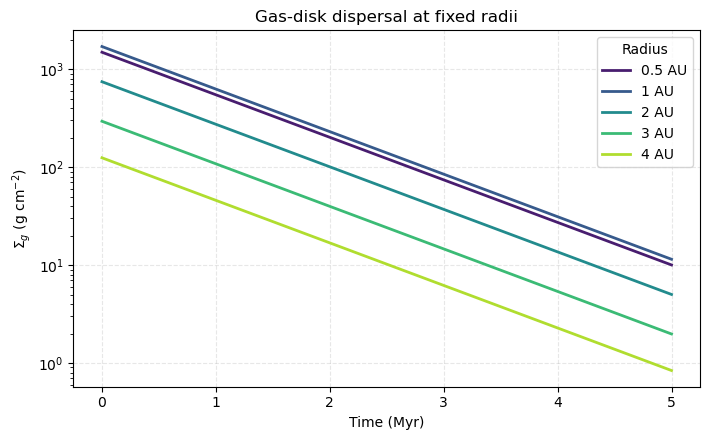

In [10]:
fig, ax = plt.subplots(figsize=(7.2, 4.5))
for a0, color in zip(initial_a_au, colors):
    sigma = disk.sigma_cgs(a0, units.myr_to_code(t_plot))
    ax.semilogy(t_plot, sigma, color=color, lw=2, label=f"{a0:g} AU")
ax.set(xlabel="Time (Myr)", ylabel=r"$\Sigma_g$ (g cm$^{-2}$)",
       title="Gas-disk dispersal at fixed radii")
ax.grid(alpha=0.3, ls="--")
ax.legend(title="Radius")
fig.tight_layout()
plt.show()

### Scope and comparison notes

This is an orbit-averaged, coplanar drag model. It uses the modified Python disk profile with `a_alpha2=0.5`; the bundled `gas.cu` has its own radial-profile implementation, so matching GENGA requires matching disk parameters and switches before comparing tracks. The previous notebook's CN08 `de_dt` belongs to tidal damping and is intentionally not used. Gas drag and Type-I are integrated independently; their rates are never combined.

## Matched check against `run_gas_drag_type1.ipynb`

This check uses that notebook's 3 AU and `sigma0_cgs=2000` setup, the current `e0`, its disk defaults, and the current mass list plus its marked mass of `2e-4 Mearth`. It compares **instantaneous** `a/|da/dt|` at `t=0` with the 5 Myr **integrated** displacement after disk decay. Timescales are in years; displacement is in AU.

The original comparison uses `i=e/2`. Our orbit-averaged drag integrator is coplanar (`i=0`), so the table shows both the original formula and a coplanar version of it. The coplanar column is the closest like-for-like check against the new drag rate. The Type-I track below is also coplanar; both integrations start at the same `a=3 AU`, `e=e0`, and use the same gas disk. No mechanisms are summed.

**Velocity normalization found during this check:** the older `AerodynamicDragModel` evaluates `vk` as `omega(a) * AU / code_time`; Kepler speed at radius `a` is `a * omega(a) * AU / code_time`. At 3 AU the old gas timescale is therefore three times the value obtained by correcting that speed, before differences between its approximate eccentricity formula and numerical orbit averaging. The table keeps the original plotted value and displays the speed-corrected analytic value separately. This diagnostic does not modify the earlier notebook or model source.

In [ ]:
from accrediff.gas_drag_type1_model import ComparisonConfig, build_comparison

check_radius_au = 3.0
check_masses_mearth = tuple(sorted(set(masses_mearth) | {2e-4}))
check_cfg = ComparisonConfig(radius_au=check_radius_au,
                             target_mass_mearth=2e-4,
                             eccentricities=(e0,), sigma0_cgs=2000.0,
                             inclination_over_e=0.5)
check_cfg_planar = replace(check_cfg, inclination_over_e=0.0)
old_model = build_comparison(check_cfg)
old_planar_model = build_comparison(check_cfg_planar)
check_disk_cfg = Gas_ModelConfig(
    particle_mass_mearth=check_masses_mearth[0], a0=check_radius_au,
    tau_decay_myr=check_cfg.tau_decay_myr,
    a_alpha1=check_cfg.a_alpha1, a_alpha2=check_cfg.a_alpha2,
    Sigma0_cgs=check_cfg.sigma0_cgs, beta=check_cfg.beta,
    def_h_1=check_cfg.h1, gamma_eff=check_cfg.gamma_eff,
    alpha_visc=check_cfg.alpha_visc, prandtl=check_cfg.prandtl,
    use_saturation=check_cfg.use_saturation,
)
check_model = Gas_build_model(check_disk_cfg)
check_disk, check_units = check_model["disk"], check_model["units"]
check_t = np.linspace(0, 5.0, n_output)


def check_integrated_track(mass_mearth, mechanism):
    """Integrate one mechanism at 3 AU with the matched, dispersing disk."""
    type1_integrator = None
    if mechanism == "type1":
        cfg_i = replace(check_disk_cfg, particle_mass_mearth=mass_mearth)
        type1_integrator = Gas_build_model(cfg_i)["integrator"]
    elif mechanism != "drag":
        raise ValueError(mechanism)

    def rhs(t, state):
        a, e = state
        a = max(float(a), a_min_stop)
        e = float(np.clip(e, 0, 0.999))
        if mechanism == "drag":
            return orbit_averaged_drag_rates(t, a, e, mass_mearth,
                                             check_disk, check_units)
        t_code = check_units.myr_to_code(t)
        a_arr, e_arr, i_arr = np.array([a]), np.array([e]), np.array([0.0])
        da = type1_integrator.da_dt_eccentric(t_code, a_arr, e_arr, i_arr)[0]
        de = type1_integrator.de_dt(t_code, a_arr, e_arr, i_arr)[0]
        return np.array([da, de]) / check_units.MYR_PER_CODE

    def inner_edge(t, state):
        return state[0] - a_min_stop
    inner_edge.terminal = True
    inner_edge.direction = -1
    def outer_edge(t, state):
        return check_disk_cfg.a_max_stop - state[0]
    outer_edge.terminal = True
    outer_edge.direction = -1

    sol = solve_ivp(rhs, (0, 5.0), (check_radius_au, e0),
                    events=(inner_edge, outer_edge), dense_output=True,
                    rtol=1e-7, atol=1e-10, max_step=0.05)
    if not sol.success:
        raise RuntimeError(sol.message)
    a = np.full_like(check_t, np.nan)
    valid = check_t <= sol.t[-1] + 1e-12
    a[valid] = sol.sol(check_t[valid])[0]
    return a


check_rows = []
check_tracks = {}
for m in check_masses_mearth:
    old_type1, old_adot, old_total = old_model["type1"].rates(m, (e0,))
    old_units, old_disk = old_type1["units"], old_type1["disk"]
    old_t0 = old_units.myr_to_code(0.0)
    old_gas_year = old_model["aerodynamic"].semimajor_axis_timescale_year(
        m, e0, old_disk, old_t0)
    old_type1_year = (check_radius_au / abs(old_total[e0])
                      * old_units.YEAR_PER_CODE)

    planar_type1, _, planar_total = old_planar_model["type1"].rates(m, (e0,))
    planar_gas_year = old_planar_model["aerodynamic"].semimajor_axis_timescale_year(
        m, e0, planar_type1["disk"], 0.0)
    planar_type1_year = (check_radius_au / abs(planar_total[e0])
                         * planar_type1["units"].YEAR_PER_CODE)

    new_da, _ = orbit_averaged_drag_rates(0.0, check_radius_au, e0, m,
                                          check_disk, check_units)
    new_gas_year = check_radius_au / abs(new_da) * 1e6
    drag_track = check_integrated_track(m, "drag")
    type1_track = check_integrated_track(m, "type1")
    check_tracks[m] = {"drag": drag_track, "type1": type1_track}
    check_rows.append((m, old_gas_year, planar_gas_year/check_radius_au, new_gas_year,
                       old_type1_year, planar_type1_year,
                       check_radius_au-drag_track[np.isfinite(drag_track)][-1],
                       check_radius_au-type1_track[np.isfinite(type1_track)][-1]))

print("t=0 timescales (yr): original i=e/2 | old formula with vk corrected and i=0 | orbit-averaged i=0")
print("mass (Mearth)  gas old   gas corrected  gas avg   Type-I old  Type-I planar  drag Δa(5 Myr)  Type-I Δa(5 Myr)")
for row in check_rows:
    m, go, gp, ga, to, tp, dd, td = row
    print(f"{m:12.0e} {go:10.3e} {gp:10.3e} {ga:10.3e} "
          f"{to:11.3e} {tp:14.3e} {dd:15.6f} {td:17.6f}")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
colors_check = plt.cm.plasma(np.linspace(0.1, 0.9, len(check_masses_mearth)))
for m, color in zip(check_masses_mearth, colors_check):
    axes[0].plot(check_t, check_radius_au-check_tracks[m]["drag"],
                 color=color, lw=2, label=fr"${m:.0e}M_\oplus$")
    axes[1].plot(check_t, check_radius_au-check_tracks[m]["type1"],
                 color=color, lw=2, label=fr"${m:.0e}M_\oplus$")
for ax, title in zip(axes, ("Gas drag only", "Type-I only")):
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set(xlabel="Time (Myr)", ylabel=r"Signed inward displacement $3-a(t)$ (AU)",
           title=title, xlim=(0, 5))
    ax.grid(alpha=0.3, ls="--")
axes[1].legend(title="Mass", fontsize=8)
fig.suptitle(fr"Matched check at 3 AU, $e_0={e0:g}$, $\Sigma_0=2000$ g cm$^{{-2}}$")
fig.tight_layout()
plt.show()